# 12 — Probability Calibration Diagnostics

Evaluate calibration of the primary grouped out-of-fold probabilities from the Notebook 03 model without reusing the same labels to fit a calibrator.

**Reproducibility note:** This notebook follows Notebook 03's primary sample definition and Random Forest pipeline. It does not overwrite or modify any earlier notebook. Run cells from top to bottom in Kaggle or Jupyter.

In [6]:
import os, glob, warnings
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, GroupKFold
from sklearn.metrics import (
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, precision_score, recall_score, f1_score, log_loss
)

# Match Notebook 03's primary population and modeling settings.
RADIUS_MIN, RADIUS_MAX = 1.0, 4.0
TEFF_MIN, TEFF_MAX = 4700, 6500
N_SPLITS = 5
THRESHOLD = 0.50
RANDOM_STATE = 42
N_ESTIMATORS = 400

# Set this manually if auto-detection finds zero or multiple candidate CSV files.
DATA_PATH = None  # e.g. "/kaggle/input/your-dataset/cumulative.csv"

def locate_koi_csv():
    if DATA_PATH is not None:
        if not os.path.exists(DATA_PATH):
            raise FileNotFoundError(f"DATA_PATH does not exist: {DATA_PATH}")
        return DATA_PATH
    candidates = sorted(
        p for p in glob.glob("/kaggle/input/**/*.csv", recursive=True)
        if ("cumulative" in os.path.basename(p).lower()
            or "koi" in os.path.basename(p).lower())
    )
    if len(candidates) == 1:
        return candidates[0]
    if not candidates:
        raise FileNotFoundError(
            "No KOI cumulative CSV found under /kaggle/input. "
            "Attach the same catalog used in Notebook 03 and set DATA_PATH manually."
        )
    print("Possible KOI CSV files:")
    for p in candidates:
        print(" -", p)
    raise ValueError("Multiple possible KOI CSVs found. Set DATA_PATH explicitly.")

def load_main_sample():
    path = locate_koi_csv()
    print("Using catalog:", path)
    raw = pd.read_csv(path, comment="#", low_memory=False)
    required = {"kepid", "koi_disposition", "koi_prad", "koi_steff"}
    missing = required - set(raw.columns)
    if missing:
        raise KeyError(f"Required columns missing: {sorted(missing)}")
    for col in ["kepid", "koi_prad", "koi_steff"]:
        raw[col] = pd.to_numeric(raw[col], errors="coerce")
    catalog = raw[
        raw["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE", "CANDIDATE"])
        & raw["kepid"].notna()
        & raw["koi_prad"].between(RADIUS_MIN, RADIUS_MAX, inclusive="both")
        & raw["koi_steff"].between(TEFF_MIN, TEFF_MAX, inclusive="both")
    ].copy()
    catalog["group"] = catalog["kepid"].astype("int64")
    labeled = catalog[
        catalog["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])
    ].copy()
    labeled["label"] = (labeled["koi_disposition"] == "CONFIRMED").astype(int)
    candidate_features = [
        "koi_period", "koi_time0bk", "koi_impact", "koi_duration",
        "koi_depth", "koi_prad", "koi_teq", "koi_insol",
        "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"
    ]
    features = [c for c in candidate_features if c in labeled.columns]
    if len(features) < 3:
        raise ValueError(f"Fewer than 3 Notebook 03 features available: {features}")
    X = labeled[features].apply(pd.to_numeric, errors="coerce")
    X = X.replace([np.inf, -np.inf], np.nan)
    drop = [c for c in X if X[c].notna().sum() == 0 or X[c].nunique(dropna=True) <= 1]
    if drop:
        print("Dropping all-missing/constant features:", drop)
        X = X.drop(columns=drop)
    y = labeled["label"].to_numpy(dtype=int)
    groups = labeled["group"].to_numpy()
    if len(np.unique(y)) != 2:
        raise ValueError("Both CONFIRMED and FALSE POSITIVE labels are required.")
    if labeled.groupby("label")["group"].nunique().min() < N_SPLITS:
        raise ValueError("Too few distinct host stars in at least one class for 5 folds.")
    print(f"Filtered catalog rows: {len(catalog):,}")
    print(f"Resolved labeled rows: {len(labeled):,}")
    print(f"Unique resolved host stars: {len(np.unique(groups)):,}")
    print("Class counts (0=false positive, 1=confirmed):")
    print(pd.Series(y).value_counts().sort_index())
    print("Features:", list(X.columns))
    return path, raw, catalog, labeled, X, y, groups

def build_model(seed=RANDOM_STATE):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=N_ESTIMATORS,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=seed,
            n_jobs=-1
        ))
    ])

def make_oof(X, y, groups, grouped=True, seed=RANDOM_STATE, n_splits=N_SPLITS):
    splitter = (
        StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        if grouped else
        StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    )
    probs = np.full(len(y), np.nan, dtype=float)
    folds = np.full(len(y), -1, dtype=int)
    split_iter = splitter.split(X, y, groups) if grouped else splitter.split(X, y)
    for fold, (tr, te) in enumerate(split_iter):
        if np.unique(y[tr]).size != 2 or np.unique(y[te]).size != 2:
            raise ValueError(
                f"Fold {fold+1} has a single class. Inspect group distribution; "
                "do not silently report fold-level class metrics."
            )
        if grouped and set(groups[tr]).intersection(set(groups[te])):
            raise RuntimeError(f"Host-star overlap in fold {fold+1}.")
        model = build_model(seed=seed)
        model.fit(X.iloc[tr], y[tr])
        probs[te] = model.predict_proba(X.iloc[te])[:, 1]
        folds[te] = fold
    if np.isnan(probs).any() or (folds < 0).any():
        raise RuntimeError("Every row must receive exactly one out-of-fold prediction.")
    return probs, folds

def metric_dict(y, p, threshold=THRESHOLD):
    pred = (p >= threshold).astype(int)
    return {
        "ROC_AUC": roc_auc_score(y, p),
        "average_precision": average_precision_score(y, p),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "Brier_score_lower_is_better": brier_score_loss(y, p),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "threshold": threshold
    }

def save_csv(df, filename):
    os.makedirs("/kaggle/working", exist_ok=True)
    path = os.path.join("/kaggle/working", filename)
    df.to_csv(path, index=False)
    print("Saved:", path)

## Aim
Assess whether the grouped out-of-fold probabilities are calibrated. Calibration asks whether predictions near (for example) 0.7 correspond to roughly 70% positive labels in comparable cases. This notebook **evaluates calibration only**; it does not fit a calibrator and score it on the same data.

Using catalog: /kaggle/input/datasets/sairakeshnagaram/koi-dataset/cumulative_2026.10.20_19.25.07.csv
Filtered catalog rows: 4,249
Resolved labeled rows: 3,195
Unique resolved host stars: 2,654
Class counts (0=false positive, 1=confirmed):
0    1229
1    1966
Name: count, dtype: int64
Features: ['koi_period', 'koi_time0bk', 'koi_impact', 'koi_duration', 'koi_depth', 'koi_prad', 'koi_teq', 'koi_insol', 'koi_steff', 'koi_slogg', 'koi_srad', 'koi_kepmag']


,validation,n_rows,n_host_stars,Brier_score_lower_is_better,log_loss_lower_is_better,ROC_AUC,average_precision
0,Host-star grouped OOF,3195,2654,0.10569,0.3439,0.92356,0.94376


Saved: /kaggle/working/12_grouped_calibration_metrics.csv


,mean_predicted_probability,observed_fraction_confirmed,absolute_gap
0,0.0380,0.0210,0.0171
1,0.1484,0.0754,0.0731
2,0.2507,0.1852,0.0655
3,0.3490,0.2945,0.0546
4,0.4556,0.3988,0.0568
5,0.5505,0.5854,0.0349
6,0.6555,0.7422,0.0867
7,0.7498,0.8208,0.0709
8,0.8521,0.9099,0.0578
9,0.9575,0.9709,0.0134


Saved: /kaggle/working/12_calibration_curve_bins.csv


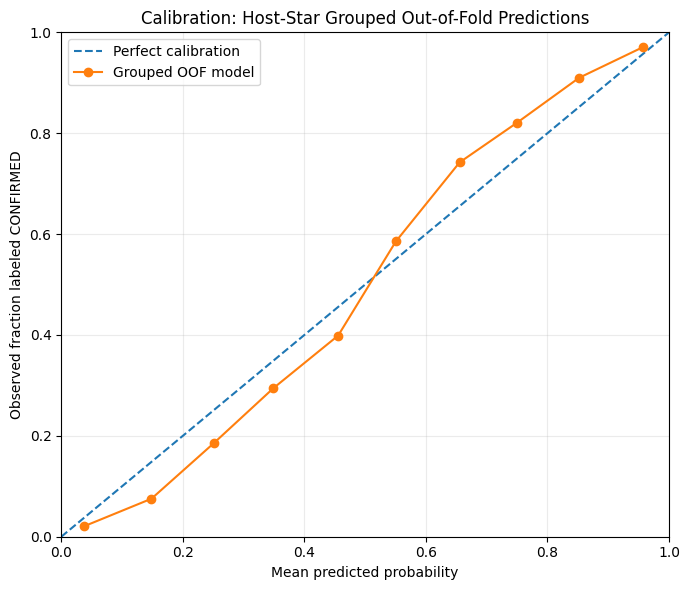

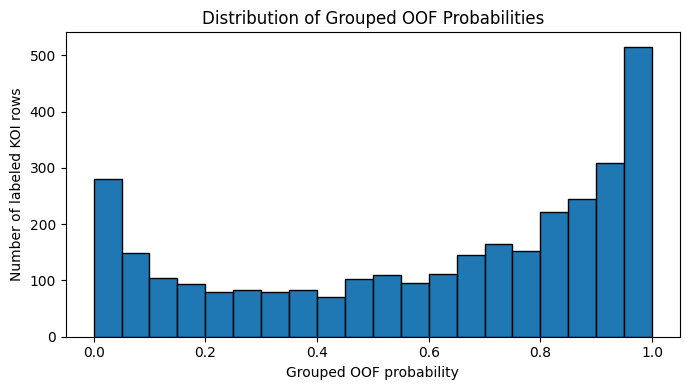

Saved: /kaggle/working/12_grouped_calibration_oof_predictions.csv


In [2]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

path, raw, catalog, labeled, X, y, groups = load_main_sample()
grouped_p, grouped_fold = make_oof(X, y, groups, grouped=True, seed=RANDOM_STATE)

calibration_metrics = pd.DataFrame([{
    "validation": "Host-star grouped OOF",
    "n_rows": len(y),
    "n_host_stars": len(np.unique(groups)),
    "Brier_score_lower_is_better": brier_score_loss(y, grouped_p),
    "log_loss_lower_is_better": log_loss(y, grouped_p, labels=[0, 1]),
    "ROC_AUC": roc_auc_score(y, grouped_p),
    "average_precision": average_precision_score(y, grouped_p)
}])
display(calibration_metrics.round(5))
save_csv(calibration_metrics, "12_grouped_calibration_metrics.csv")

# Uniform probability bins; empty bins are omitted by sklearn.
n_bins = 10
fraction_positive, mean_predicted = calibration_curve(
    y, grouped_p, n_bins=n_bins, strategy="uniform"
)
calibration_table = pd.DataFrame({
    "mean_predicted_probability": mean_predicted,
    "observed_fraction_confirmed": fraction_positive,
    "absolute_gap": np.abs(mean_predicted - fraction_positive)
})
display(calibration_table.round(4))
save_csv(calibration_table, "12_calibration_curve_bins.csv")

plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.plot(mean_predicted, fraction_positive, marker="o", label="Grouped OOF model")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction labeled CONFIRMED")
plt.title("Calibration: Host-Star Grouped Out-of-Fold Predictions")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(grouped_p, bins=np.linspace(0, 1, 21), edgecolor="black")
plt.xlabel("Grouped OOF probability")
plt.ylabel("Number of labeled KOI rows")
plt.title("Distribution of Grouped OOF Probabilities")
plt.tight_layout()
plt.show()

oof = pd.DataFrame({
    "row_index": labeled.index, "host_id": groups,
    "true_label": y, "grouped_oof_probability": grouped_p,
    "fold": grouped_fold
})
save_csv(oof, "12_grouped_calibration_oof_predictions.csv")

## Interpretation guardrails
- Calibration is evaluated against the catalog labels, not independently verified physical truth.
- Brier score and log loss combine calibration and aspects of discrimination; neither alone proves calibration.
- The reliability diagram depends on binning and sample size. Include bin counts when discussing sparse bins.
- Do not claim that probabilities are calibrated for unresolved CANDIDATE rows; candidates were not used in this supervised evaluation.